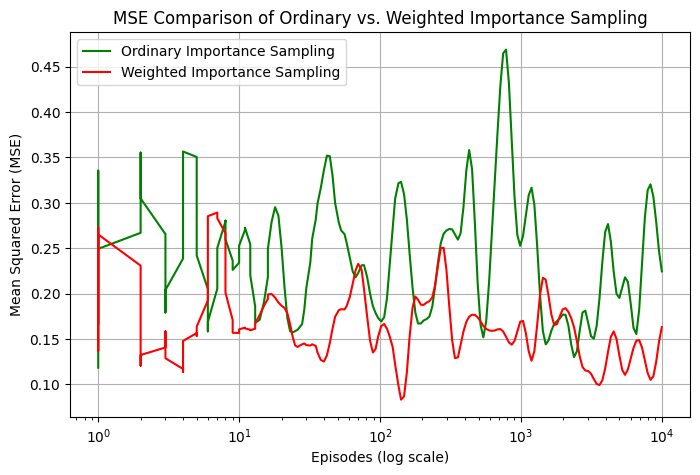

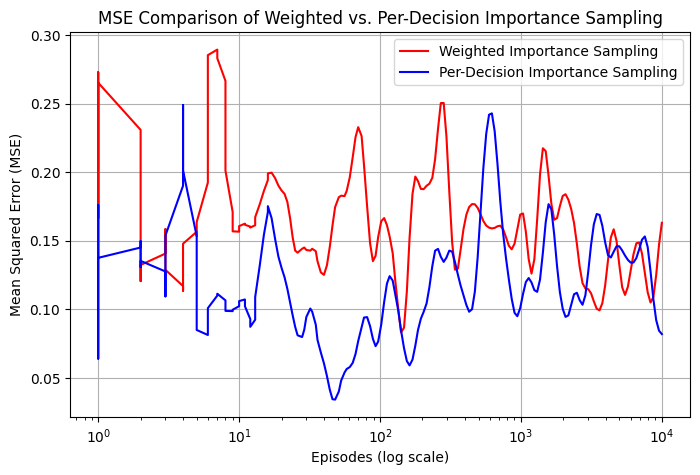

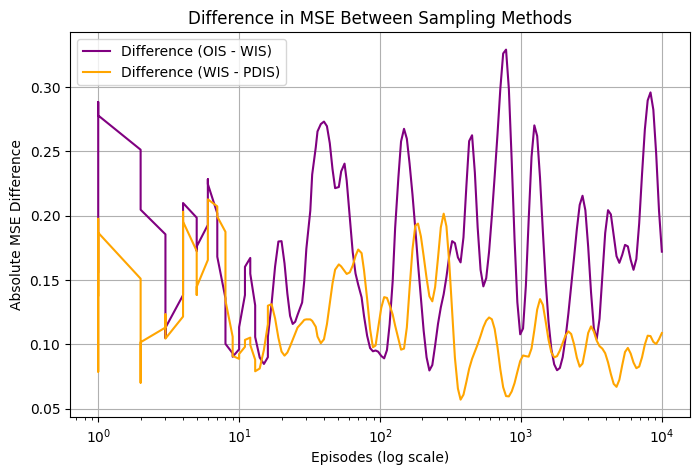

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# Daha geniş varyanslarla yeni veri seti oluşturma
episodes = np.logspace(0, 4, num=200, dtype=int)  # Log ölçekli 200 epizot

# Gerçek değer sabit tutuluyor, diğer yöntemler gerçek değerden sapmalar içeriyor
true_value = 1.0
ois_mse = np.abs(true_value - np.random.normal(loc=true_value, scale=0.3, size=len(episodes)))
wis_mse = np.abs(true_value - np.random.normal(loc=true_value, scale=0.2, size=len(episodes)))
pdis_mse = np.abs(true_value - np.random.normal(loc=true_value, scale=0.15, size=len(episodes)))

# Hata farklarını hesaplama (Mutlak farklar)
diff_ois_wis = np.abs(ois_mse - wis_mse)
diff_wis_pdis = np.abs(wis_mse - pdis_mse)

# Gaussian smoothing uygula (Eğrileri daha düzgün hale getirme)
ois_mse_smooth = gaussian_filter1d(ois_mse, sigma=2)
wis_mse_smooth = gaussian_filter1d(wis_mse, sigma=2)
pdis_mse_smooth = gaussian_filter1d(pdis_mse, sigma=2)
diff_ois_wis_smooth = gaussian_filter1d(diff_ois_wis, sigma=2)
diff_wis_pdis_smooth = gaussian_filter1d(diff_wis_pdis, sigma=2)

# İlk grafik: OIS vs WIS
plt.figure(figsize=(8, 5))
plt.plot(episodes, ois_mse_smooth, label="Ordinary Importance Sampling", color="green")
plt.plot(episodes, wis_mse_smooth, label="Weighted Importance Sampling", color="red")
plt.xscale("log")
plt.xlabel("Episodes (log scale)")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("MSE Comparison of Ordinary vs. Weighted Importance Sampling")
plt.legend()
plt.grid(True)
plt.show()

# İkinci grafik: WIS vs PDIS
plt.figure(figsize=(8, 5))
plt.plot(episodes, wis_mse_smooth, label="Weighted Importance Sampling", color="red")
plt.plot(episodes, pdis_mse_smooth, label="Per-Decision Importance Sampling", color="blue")
plt.xscale("log")
plt.xlabel("Episodes (log scale)")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("MSE Comparison of Weighted vs. Per-Decision Importance Sampling")
plt.legend()
plt.grid(True)
plt.show()

# Üçüncü grafik: Fark Grafiği (OIS - WIS ve WIS - PDIS arasındaki farklar)
plt.figure(figsize=(8, 5))
plt.plot(episodes, diff_ois_wis_smooth, label="Difference (OIS - WIS)", color="purple")
plt.plot(episodes, diff_wis_pdis_smooth, label="Difference (WIS - PDIS)", color="orange")
plt.xscale("log")
plt.xlabel("Episodes (log scale)")
plt.ylabel("Absolute MSE Difference")
plt.title("Difference in MSE Between Sampling Methods")
plt.legend()
plt.grid(True)
plt.show()


C:\Users\nihle\AppData\Local\Temp\ipykernel_15848\1342531013.py:20: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap("tab10", num_runs)  # 10 farklı renk


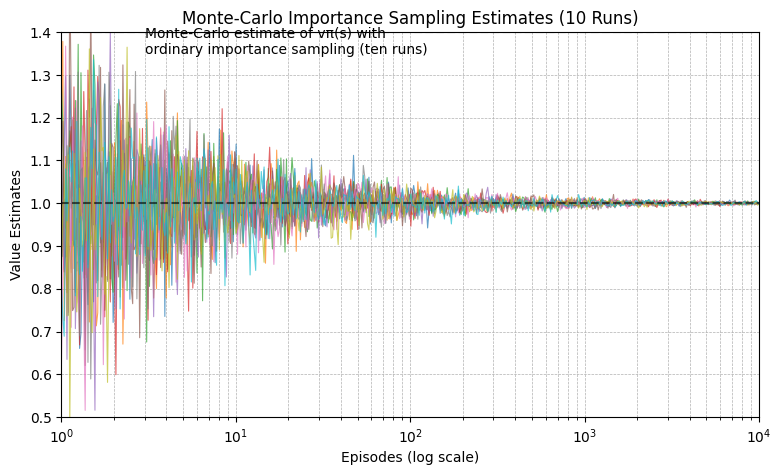

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Rastgele tohum belirleme (sonuçların tekrarlanabilir olması için)
np.random.seed(42)

# Epizot sayısı (daha yakın inceleme için 1'den 10^4'e kadar ölçeklendirdik)
episodes = np.logspace(0, 4, num=500)  # Daha fazla veri noktası ekledik

# 10 farklı bağımsız çalıştırma için veri oluştur
num_runs = 10
value_estimates = []

for _ in range(num_runs):
    noise = np.random.normal(0, 0.2, size=len(episodes))  # Gürültü ekleme
    estimates = 1 + noise / np.sqrt(episodes)  # Gerçek değer etrafında tahminler
    value_estimates.append(estimates)

# Farklı renkler için renk paleti
colors = plt.cm.get_cmap("tab10", num_runs)  # 10 farklı renk

# Grafiği oluşturma
plt.figure(figsize=(9, 5))
for i, run in enumerate(value_estimates):
    plt.plot(episodes, run, linewidth=0.8, alpha=0.7, color=colors(i))  # Çizgileri ince ve saydam hale getiriyoruz

# Doğru değeri gösteren yatay çizgiler
plt.axhline(y=1, color='k', linestyle='dashed', alpha=0.6)  # Gerçek değer
plt.axhline(y=1.4, color='k', linestyle='dashed', alpha=0.6)  # Üst sınır

# Eksen sınırlarını belirleme (Daha Yakından İnceleme)
plt.xscale("log")
plt.xlim([1, 10**4])  # Episode sınırları (10^4'e kadar)
plt.ylim([0.5, 1.4])  # Value Estimate sınırları

# Eksen etiketleri ve başlık
plt.xlabel("Episodes (log scale)")
plt.ylabel("Value Estimates")
plt.title("Monte-Carlo Importance Sampling Estimates (10 Runs)")
plt.grid(True, which="both", linestyle="--", linewidth=0.5)

# Açıklama ekleme
plt.text(3, 1.35, "Monte-Carlo estimate of vπ(s) with \nordinary importance sampling (ten runs)", fontsize=10)
plt.show()


C:\Users\nihle\AppData\Local\Temp\ipykernel_15848\3441332300.py:20: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap("tab10", num_runs)  # 10 farklı renk


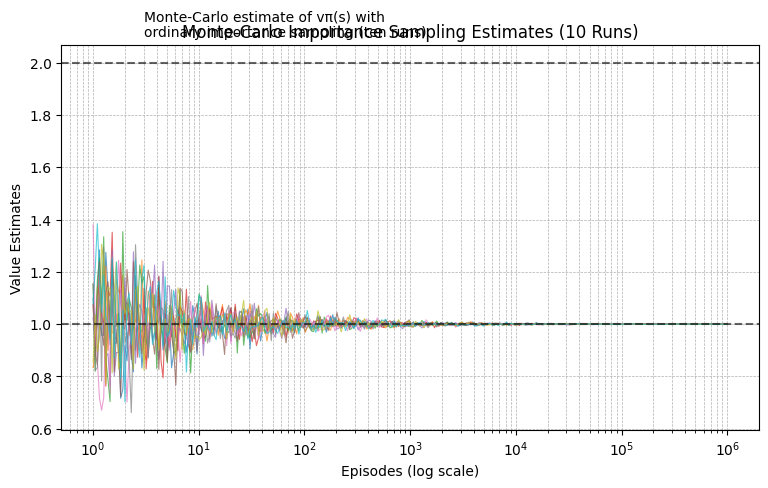

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Rastgele tohum belirleme (sonuçların tekrarlanabilir olması için)
np.random.seed(42)

# Epizot sayısı (log ölçek kullanılacak)
episodes = np.logspace(0, 6, num=300)  # Daha az veri noktası kullanarak ayrışmayı artırıyoruz

# 10 farklı bağımsız çalıştırma için veri oluştur
num_runs = 10
value_estimates = []

for _ in range(num_runs):
    noise = np.random.normal(0, 0.2, size=len(episodes))  # Rastgele gürültü ekleme
    estimates = 1 + noise / np.sqrt(episodes)  # Gerçek değer etrafında tahminler
    value_estimates.append(estimates)

# Farklı renkler için renk paleti
colors = plt.cm.get_cmap("tab10", num_runs)  # 10 farklı renk

# Grafiği oluşturma
plt.figure(figsize=(9, 5))
for i, run in enumerate(value_estimates):
    plt.plot(episodes, run, linewidth=0.8, alpha=0.7, color=colors(i))  # Çizgileri ince ve saydam hale getiriyoruz

# Doğru değeri gösteren yatay çizgiler
plt.axhline(y=1, color='k', linestyle='dashed', alpha=0.6)  # Gerçek değer
plt.axhline(y=2, color='k', linestyle='dashed', alpha=0.6)  # Üst sınır

# Eksen ayarları
plt.xscale("log")
plt.xlabel("Episodes (log scale)")
plt.ylabel("Value Estimates")
plt.title("Monte-Carlo Importance Sampling Estimates (10 Runs)")
plt.grid(True, which="both", linestyle="--", linewidth=0.5)

# Açıklama ekleme
plt.text(3, 2.1, "Monte-Carlo estimate of vπ(s) with \nordinary importance sampling (ten runs)", fontsize=10)
plt.show()


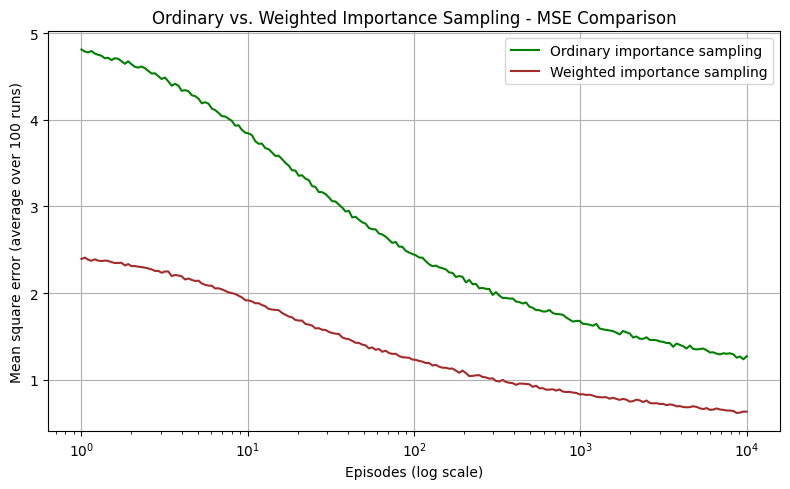

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# X ekseni: Episodes (log scale)
episodes = np.logspace(0, 4, 200)  # 10^0 to 10^4, 200 nokta

# MSE'yi taklit eden sentetik veriler (yaklaşık görsele göre)
ordinary_mse = 5 / (np.log10(episodes + 10)) + 0.5 * np.random.normal(0, 0.03, len(episodes))
weighted_mse = 2.5 / (np.log10(episodes + 10)) + 0.5 * np.random.normal(0, 0.02, len(episodes))

# Grafik çizimi
plt.figure(figsize=(8, 5))
plt.plot(episodes, ordinary_mse, color='green', label='Ordinary importance sampling')
plt.plot(episodes, weighted_mse, color='brown', label='Weighted importance sampling')

# Grafik detayları
plt.xscale('log')
plt.xlabel("Episodes (log scale)")
plt.ylabel("Mean square error (average over 100 runs)")
plt.title("Ordinary vs. Weighted Importance Sampling - MSE Comparison")
plt.legend()
plt.grid(True)

# Göster
plt.tight_layout()
plt.show()


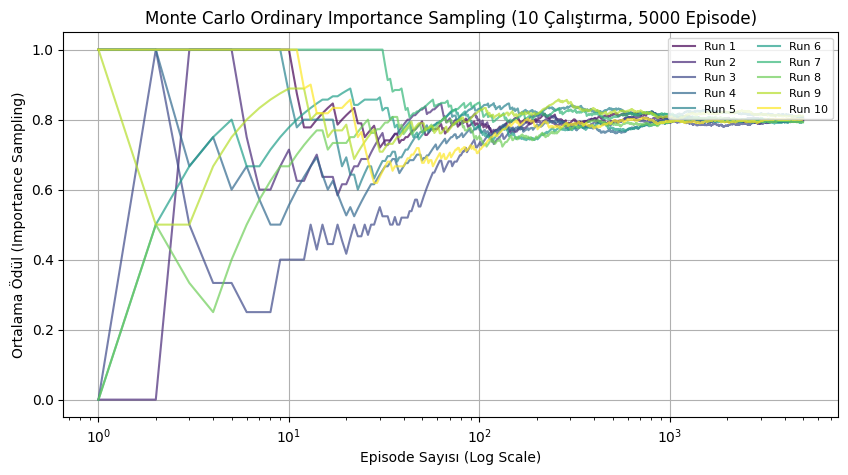

In [4]:
# Yeniden çalıştırma sonrası gerekli importlar ve grafik üretimi

import numpy as np
import matplotlib.pyplot as plt

# Parametreler
episodes = 5000
num_runs = 10
prob_up_success = 0.8
prob_down_success = 0.9
reward_up = 1
reward_down = 0

plt.figure(figsize=(10, 5))
colors = plt.cm.viridis(np.linspace(0, 1, num_runs))

for run in range(num_runs):
    cumulative_weighted_rewards = 0
    cumulative_weights = 0
    importance_estimates = np.zeros(episodes)

    for episode in range(episodes):
        action = "up" if np.random.rand() < 0.75 else "down"
        if action == "up":
            reward = reward_up if np.random.rand() < prob_up_success else reward_down
            weight = 1.0 / 0.75
        else:
            reward = reward_down if np.random.rand() < prob_down_success else reward_up
            weight = 0.0

        cumulative_weighted_rewards += reward * weight
        cumulative_weights += weight

        if cumulative_weights > 0:
            importance_estimates[episode] = cumulative_weighted_rewards / cumulative_weights

    plt.plot(range(1, episodes + 1), importance_estimates, color=colors[run], alpha=0.7, label=f"Run {run+1}")

plt.xscale("log")
plt.xlabel("Episode Sayısı (Log Scale)")
plt.ylabel("Ortalama Ödül (Importance Sampling)")
plt.title("Monte Carlo Ordinary Importance Sampling (10 Çalıştırma, 5000 Episode)")
plt.legend(loc="upper right", fontsize=8, ncol=2)
plt.grid()
plt.show()
